# PINN para el flujo de Couette estacionario con neurodiffeq


In [2]:
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt

from neurodiffeq import diff
from neurodiffeq.solvers import Solver1D
from neurodiffeq.conditions import DirichletBVP
from neurodiffeq.networks import FCNN
from neurodiffeq.monitors import Monitor1D
from neurodiffeq.callbacks import MonitorCallback
from neurodiffeq.generators import Generator1D

print("Imports correctos")

Imports correctos


C:\Users\carlo\anaconda3\Lib\site-packages\torch\__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


## Definimos la ecuación diferencial

Resolvemos: $\frac{d^2u}{dy^2} = 0$

In [4]:
def ode(u, y):
    return diff(u, y, order=2)


## Condiciones de contorno

- $u(0) = 0$ → placa inferior fija
- $u(1) = 1$ → placa superior móvil

In [6]:
# DirichletBVP(y0, u(y0), y1, u(y1))
V=1.0
condition = DirichletBVP(0, 0.0, 1, V)

## Red neuronal

2 capas de 32 neuronas con Tanh — suficiente para aprender u(y) = y.

In [8]:

#Red usando Tanjente hiperbolica
net = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(32, 32),
    actv=nn.SiLU
)

#Red usando Sigmoid Linear Unit 
print(net)

FCNN(
  (NN): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): SiLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): SiLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## Generadores de puntos de colocación

Los **generators** controlan cómo se muestrean los puntos interiores donde se evalúa el residuo de la EDP.

- `method='uniform'` → puntos aleatorios uniformes (renovados cada época, más exploración)
- `method='equally-spaced'` → puntos fijos y equidistantes (más estable, bueno para validación)
- `method='equally-spaced-noisy'` → equidistantes + ruido (equilibrio entre ambos)

In [10]:
# 128 puntos aleatorios uniformes en [0, 1] para entrenamiento
train_generator = Generator1D(128, t_min=0.0, t_max=1.0, method='uniform')

# 256 puntos equidistantes fijos en [0, 1] para validación
valid_generator = Generator1D(256, t_min=0.0, t_max=1.0, method='equally-spaced')

print(f"Train generator: {train_generator}")
print(f"Valid generator: {valid_generator}")

Train generator: Generator1D(size=128, t_min=0.0, t_max=1.0, method='uniform', noise_std=0.001953125)
Valid generator: Generator1D(size=256, t_min=0.0, t_max=1.0, method='equally-spaced', noise_std=0.0009765625)


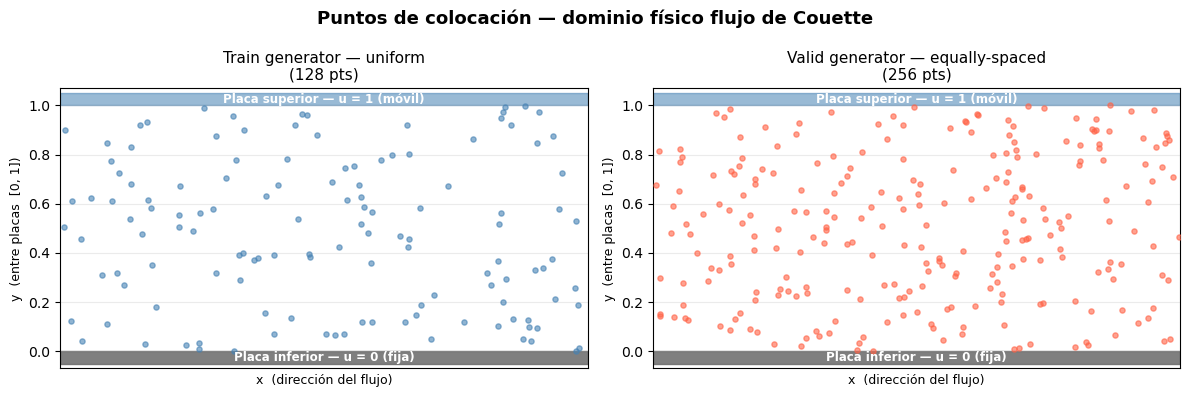

In [11]:
# Visualización de los puntos de colocación en el dominio físico del flujo de Couette
pts_train = train_generator.get_examples().detach().numpy()
pts_valid = valid_generator.get_examples().detach().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, pts, color, title in zip(
    axes,
    [pts_train, pts_valid],
    ['steelblue', 'tomato'],
    [f'Train generator — uniform\n({len(pts_train)} pts)',
     f'Valid generator — equally-spaced\n({len(pts_valid)} pts)']
):
    # Coordenada x aleatoria solo para distribuir visualmente en el canal
    x_pos = np.random.uniform(0.0, 1.0, size=len(pts))

    # Placas superior e inferior
    ax.axhspan(-0.05, 0.0, color='dimgray',   alpha=0.85)  # placa inferior fija
    ax.axhspan(1.0,  1.05, color='steelblue',  alpha=0.55)  # placa superior móvil

    # Puntos de colocación
    ax.scatter(x_pos, pts, s=14, alpha=0.6, color=color, zorder=3)

    # Etiquetas de las placas
    ax.text(0.5, -0.025, 'Placa inferior — u = 0 (fija)',
            ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    ax.text(0.5,  1.025, 'Placa superior — u = 1 (móvil)',
            ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.07, 1.07)
    ax.set_xlabel('x  (dirección del flujo)', fontsize=9)
    ax.set_ylabel('y  (entre placas  [0, 1])', fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_xticks([])
    ax.grid(True, alpha=0.25)

plt.suptitle('Puntos de colocación — dominio físico flujo de Couette',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
import torch
from neurodiffeq.generators import PredefinedGenerator

# Ej.: puntos concentrados cerca de las placas (y=0, y=1) y más dispersos en el centro
y_custom = torch.tensor([0.00, 0.02, 0.05, 0.10, 0.20,
                         0.35, 0.50, 0.65,
                         0.80, 0.90, 0.95, 0.98, 1.00])

train_generator = PredefinedGenerator(y_custom)

## Solver y entrenamiento

Training Progress:   0%|          | 0/1000 [00:00<?, ?it/s]

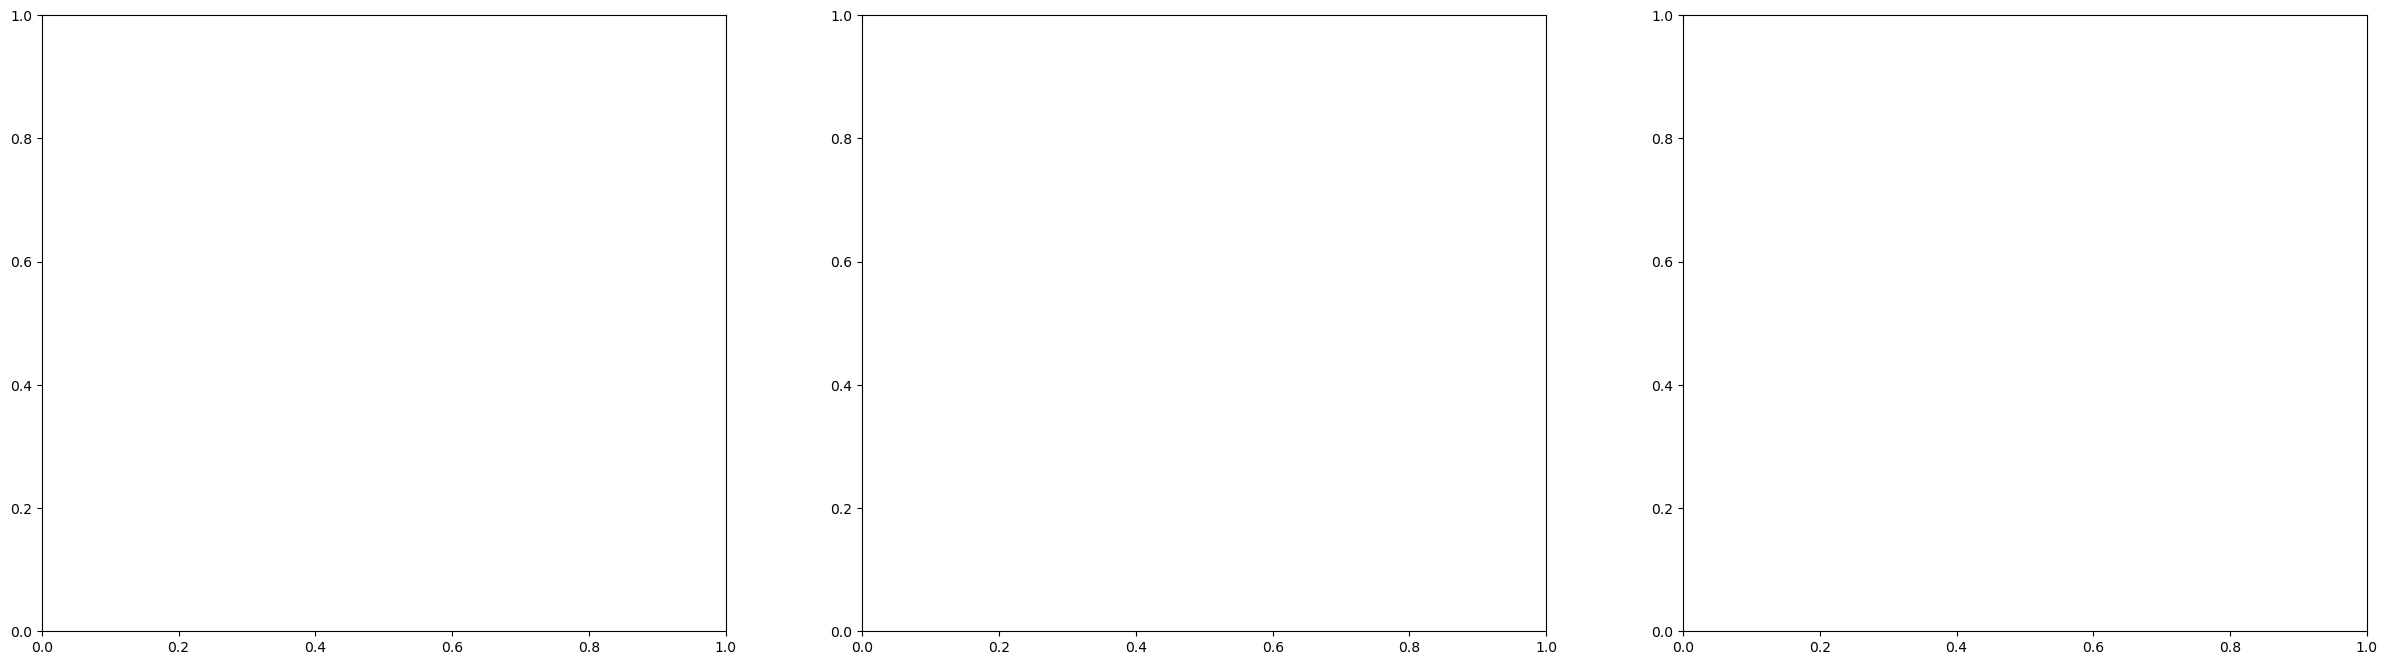

In [14]:
# Monitor: muestra la solución y la pérdida cada 100 épocas
monitor = Monitor1D(t_min=0.0, t_max=1.0,check_every=100)

solver = Solver1D(
    ode_system=ode,
    conditions=[condition],
    t_min=0.0,               # dominio [0, 1] — igual que DirichletBVP
    t_max=1.0,
    nets=[net],
    train_generator=train_generator,   # puntos de colocación (entrenamiento)
    valid_generator=valid_generator,   # puntos de colocación (validación)
)

solver.fit(max_epochs=1000)
solution = solver.get_solution(best=True)

C:\Users\carlo\anaconda3\Lib\site-packages\neurodiffeq\ode.py:260: FutureWarning: The `solve_system` function is deprecated, use a `neurodiffeq.solvers.Solver1D` instance instead
  warnings.warn(
C:\Users\carlo\anaconda3\Lib\site-packages\neurodiffeq\solvers.py:459: UserWarning: Passing `monitor` is deprecated, use a MonitorCallback and pass a list of callbacks instead
  warnings.warn("Passing `monitor` is deprecated, "


Training Progress:   0%|          | 0/200 [00:00<?, ?it/s]

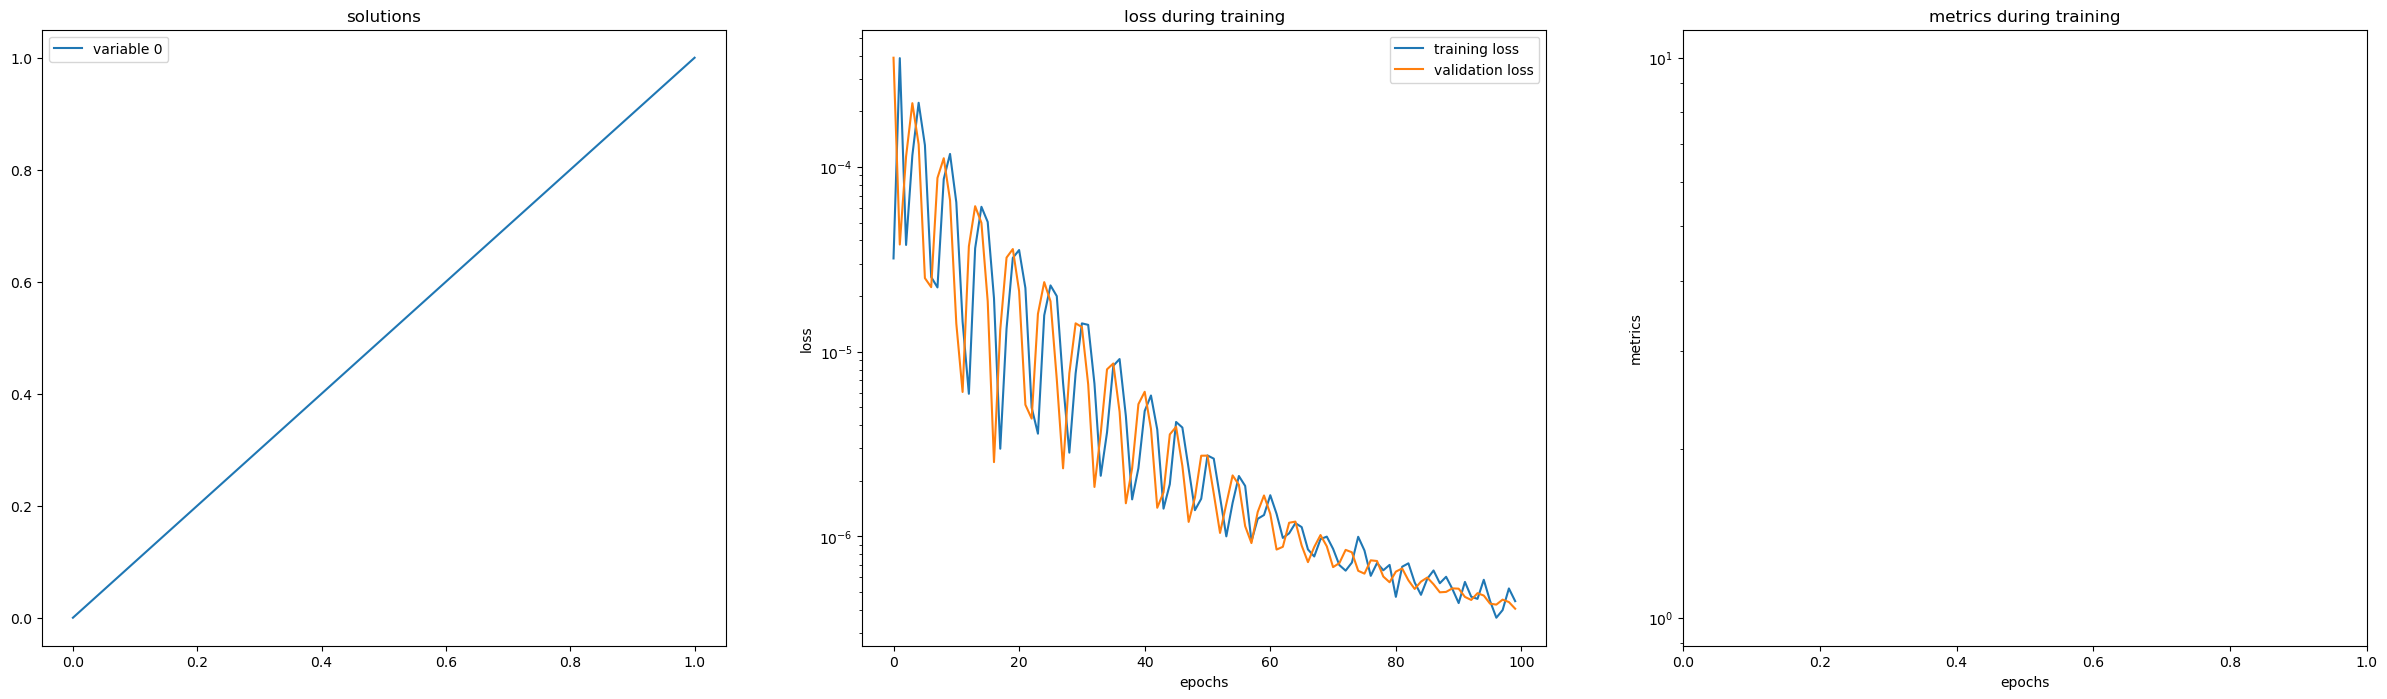

In [15]:
from neurodiffeq.ode import solve

solution, loss_history = solve(
    ode,
    condition,
    t_min=0.0,
    t_max=np.pi,
    net=net,
    monitor=Monitor1D(t_min=0.0, t_max=1.0,check_every=100),
    max_epochs=200,
    return_best=True,
)

## loss

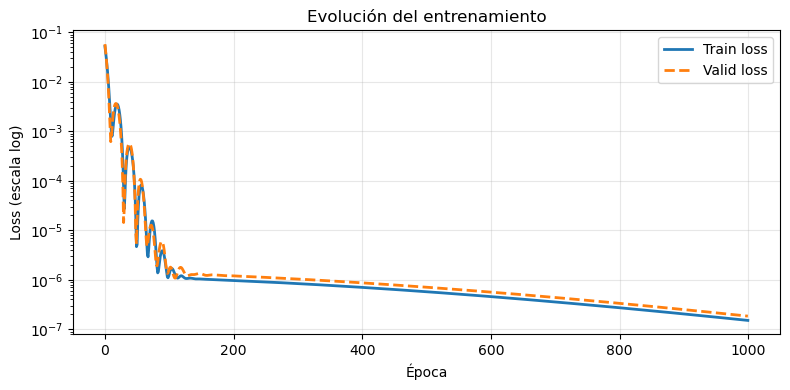

In [17]:
loss_history = solver.metrics_history

plt.figure(figsize=(8, 4))
plt.semilogy(loss_history['train_loss'], label='Train loss', linewidth=2)
plt.semilogy(loss_history['valid_loss'], label='Valid loss', linewidth=2, linestyle='--')
plt.xlabel('Época'); plt.ylabel('Loss (escala log)')
plt.title('Evolución del entrenamiento')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Solucion PINN

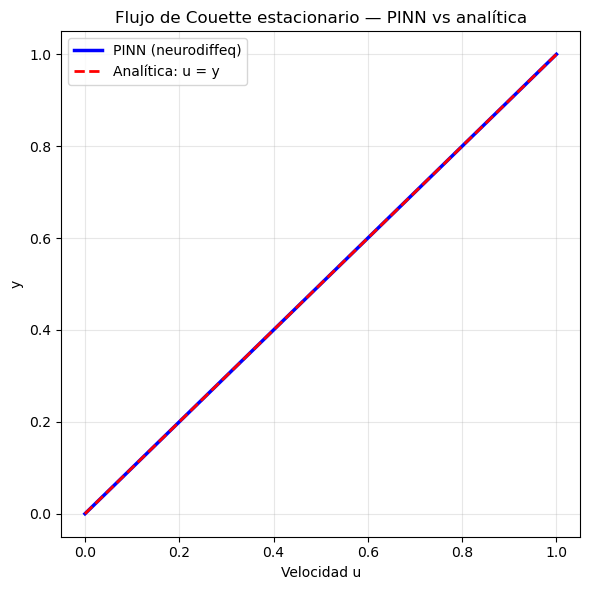

Error máximo respecto a u(y) = y:  2.52e-05


In [19]:
y_test = np.linspace(0, 1, 200)
u_pred = solution(y_test, to_numpy=True)
u_anal = V*y_test  # solución analítica: u(y) = y

plt.figure(figsize=(6, 6))
plt.plot(u_pred, y_test, 'b-', linewidth=2.5, label='PINN (neurodiffeq)')
plt.plot(u_anal, y_test, 'r--', linewidth=2, label='Analítica: u = y')
plt.xlabel('Velocidad u'); plt.ylabel('y')
plt.title('Flujo de Couette estacionario — PINN vs analítica')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

error = np.max(np.abs(u_pred - u_anal))
print(f'Error máximo respecto a u(y) = y:  {error:.2e}')

## Comparación PINN vs analítica para distintos V

Entrenamos una PINN independiente para cada `V` y la comparamos con la solución analítica  
$u(y) = V \cdot y$  
en el dominio $y \in [0,1]$ con condiciones de contorno $u(0)=0$ y $u(1)=V$.

Entrenando PINN para V = 1.0 ...


Training Progress:   0%|          | 0/1000 [00:00<?, ?it/s]

  Error máx vs analítica: 3.65e-06
Entrenando PINN para V = 2.0 ...


Training Progress:   0%|          | 0/1000 [00:00<?, ?it/s]

  Error máx vs analítica: 3.65e-06
Entrenando PINN para V = 4.0 ...


Training Progress:   0%|          | 0/1000 [00:00<?, ?it/s]

  Error máx vs analítica: 3.65e-06


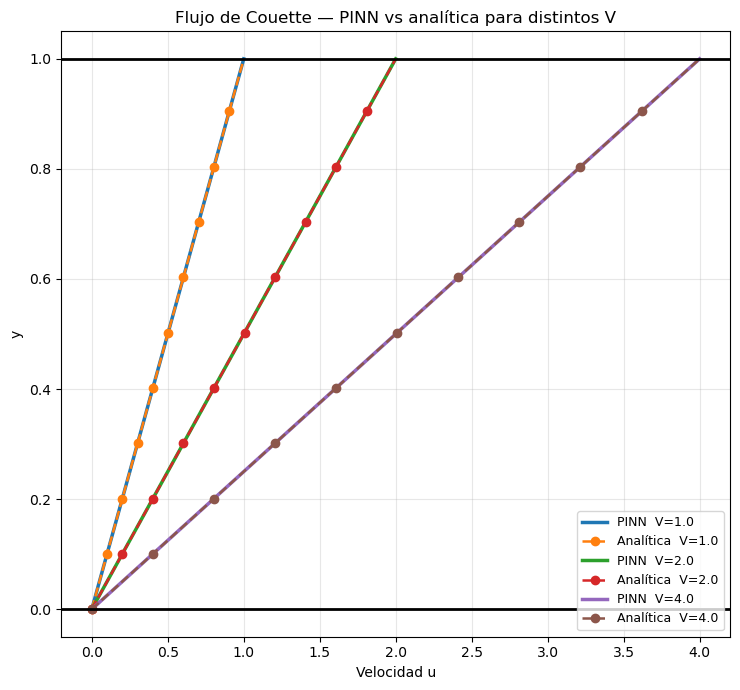

In [21]:
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt

from neurodiffeq import diff
from neurodiffeq.solvers import Solver1D
from neurodiffeq.conditions import DirichletBVP
from neurodiffeq.networks import FCNN
from neurodiffeq.generators import Generator1D


def entrenar_pinn_couette(V, max_epochs=1000, seed=0):
    """Entrena una PINN para u'' = 0 con u(0)=0 y u(1)=V."""
    import torch
    torch.manual_seed(seed)

    def ode(u, y):
        return diff(u, y, order=2)

    condition = DirichletBVP(0, 0.0, 1, V)

    net = FCNN(
        n_input_units=1,
        n_output_units=1,
        hidden_units=(32, 32),
        actv=nn.SiLU
    )

    train_gen = Generator1D(128, t_min=0.0, t_max=1.0, method='uniform')
    valid_gen = Generator1D(256, t_min=0.0, t_max=1.0, method='equally-spaced')

    solver = Solver1D(
        ode_system=ode,
        conditions=[condition],
        t_min=0.0, t_max=1.0,
        nets=[net],
        train_generator=train_gen,
        valid_generator=valid_gen,
    )
    solver.fit(max_epochs=max_epochs)
    return solver.get_solution(best=True)


# Valores de V a comparar
V_values = [1.0, 2.0, 4.0]

# Colores: PINN en tonos fríos, analítica en tonos cálidos / oscuros
pinn_colors = ['#1f77b4', '#2ca02c', '#9467bd']   # azul, verde, morado
anal_colors = ['#ff7f0e', '#d62728', '#8c564b']   # naranja, rojo, marrón

y_test = np.linspace(0, 1, 200)

plt.figure(figsize=(7.5, 7))

for V, cp, ca in zip(V_values, pinn_colors, anal_colors):
    print(f'Entrenando PINN para V = {V} ...')
    sol = entrenar_pinn_couette(V, max_epochs=1000)
    u_pred = sol(y_test, to_numpy=True)
    u_anal = V * y_test

    # PINN: línea continua
    plt.plot(u_pred, y_test, color=cp, linewidth=2.5,
             label=f'PINN  V={V}')
    # Analítica: línea discontinua + marcadores espaciados (otro color)
    plt.plot(u_anal, y_test, color=ca, linestyle='--', linewidth=1.8,
             marker='o', markevery=20, markersize=6,
             label=f'Analítica  V={V}')

    err = np.max(np.abs(u_pred - u_anal))
    print(f'  Error máx vs analítica: {err:.2e}')

plt.axhline(0, color='k', linewidth=2)
plt.axhline(1, color='k', linewidth=2)
plt.xlabel('Velocidad u')
plt.ylabel('y')
plt.title('Flujo de Couette — PINN vs analítica para distintos V')
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
